### Practice: Parameter Efficient Fine-Tuning
In this notebook, you're gonna fine-tune large language models within limited GPU memory.

In [1]:
%pip install --upgrade peft bitsandbytes

import torch
import torch.nn as nn
import torch.nn.functional as F

import matplotlib.pyplot as plt
from matplotlib.axes import Axes
from IPython.display import clear_output

import transformers
from tqdm.auto import tqdm, trange
assert torch.cuda.is_available(), "you need cuda for this part"
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


/home/bojkoar/ysda_nlp_course/.venv3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
model_name = 'unsloth/Qwen3-8B-Base-bnb-4bit'
tokenizer: transformers.models.qwen2.tokenization_qwen2.Qwen2Tokenizer = transformers.AutoTokenizer.from_pretrained(model_name)
tokenizer.pad_token_id = tokenizer.eos_token_id

# the main model weights are loaded in 4-bit precision - but we can still tune LoRAs later
model = transformers.AutoModelForCausalLM.from_pretrained(
    model_name, device_map='auto', low_cpu_mem_usage=True, dtype=torch.float32,
    quantization_config=transformers.BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4"),
)
for param in model.parameters():
    param.requires_grad=False
model.gradient_checkpointing_enable()  # only store a small subset of activations, re-compute the rest.
model.enable_input_require_grads()     # override an implementation quirk in gradient checkpoints that disables backprop unless inputs require grad
# more on gradient checkpointing: https://pytorch.org/docs/stable/checkpoint.html https://arxiv.org/abs/1604.06174

/home/bojkoar/ysda_nlp_course/.venv3.12/lib/python3.12/site-packages/transformers/quantizers/auto.py:279: UserWarning: You passed `quantization_config` or equivalent parameters to `from_pretrained` but the model you're loading already has a `quantization_config` attribute. The `quantization_config` from the model will be used.
  warnings.warn(warning_msg)
[W1120 20:42:32.939105510 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 3 while trying to allocate 2489319424 bytes (free: 526516224, total: 8172666880).
Loading weights: 100%|██████████| 399/399 [00:01<00:00, 220.74it/s]


### Prompt tuning: the story of a fox (1 point)

![img](https://i.imgur.com/Ux3qQAu.png) (source: theodd1souts.fandom.com)

In [3]:
prompt = 'A quick brown fox'
batch = tokenizer(prompt, return_tensors='pt', return_token_type_ids=False).to(device)

for i in range(10):
    next_token = model(**batch).logits[0, -1].argmax(-1).reshape(1, 1)
    batch['input_ids'] = torch.cat([batch['input_ids'], next_token], dim=-1)
    batch['attention_mask'] = torch.cat([batch['attention_mask'], torch.ones_like(next_token)], dim=-1)

print("\nOutput:", tokenizer.decode(batch['input_ids'][0].cpu().numpy().tolist()))


Output: A quick brown fox jumps over the lazy dog. The quick brown fox


What a blatant lie! This particular fox assures you that it didn't in fact jump over the lazy dog. No, sir! The fox was just minding its own business. __Your task is to train the model to say truth: no dog was jumped over today.__

In [4]:
the_truth = "A quick brown fox did not jump over the lazy dog. Besides, that dog deserved it anyway!"
batch = tokenizer(the_truth, return_tensors='pt', return_token_type_ids=False).to(device)
outputs = model(**batch)

next_word_logits = outputs.logits[:, :-1]
true_next_tokens = batch['input_ids'][:, 1:]
loss = F.cross_entropy(next_word_logits.flatten(0, 1), true_next_tokens.flatten(0, 1))

print("Loss:", loss)

Loss: tensor(3.5414, device='cuda:0', grad_fn=<NllLossBackward0>)


Except, we can't train the entire model - that would be 28GB gradients in float32. Instead, let's run [prompt tuning](https://arxiv.org/abs/2104.08691).

![img](https://i.imgur.com/VwNNKnb.png)


In [5]:
a = torch.rand((5, 2, 3))
b = torch.rand((1, 5, 3))
b_exp = b.expand(a.shape[0], *b.shape[1:])
torch.cat([a, b_exp], dim=-2)

tensor([[[0.7504, 0.3164, 0.5928],
         [0.0617, 0.3574, 0.6110],
         [0.1749, 0.4040, 0.6984],
         [0.5740, 0.5827, 0.7630],
         [0.1680, 0.2719, 0.7331],
         [0.4860, 0.6953, 0.7040],
         [0.9524, 0.5878, 0.8161]],

        [[0.5344, 0.3741, 0.0926],
         [0.7002, 0.0983, 0.5479],
         [0.1749, 0.4040, 0.6984],
         [0.5740, 0.5827, 0.7630],
         [0.1680, 0.2719, 0.7331],
         [0.4860, 0.6953, 0.7040],
         [0.9524, 0.5878, 0.8161]],

        [[0.8898, 0.2185, 0.1498],
         [0.0767, 0.0072, 0.8164],
         [0.1749, 0.4040, 0.6984],
         [0.5740, 0.5827, 0.7630],
         [0.1680, 0.2719, 0.7331],
         [0.4860, 0.6953, 0.7040],
         [0.9524, 0.5878, 0.8161]],

        [[0.8939, 0.5934, 0.4040],
         [0.0828, 0.4100, 0.0973],
         [0.1749, 0.4040, 0.6984],
         [0.5740, 0.5827, 0.7630],
         [0.1680, 0.2719, 0.7331],
         [0.4860, 0.6953, 0.7040],
         [0.9524, 0.5878, 0.8161]],

        [[0.

In [6]:
class WordEmbeddingsWithLearnedPrompts(nn.Module):
    """
    To perform prompt tuning, you will need to replace model's original word embeddings with a layer - THIS layer
     - that inserts trainable prompts instead of the first N token embeddings. """

    def __init__(self, word_embeddings: nn.Embedding, num_prompts: int):
        super().__init__()
        self.original_word_embeddings = word_embeddings
        self.num_prompts = num_prompts
        self.learnable_prompts = nn.Parameter(
            torch.empty(
                1, num_prompts, word_embeddings.embedding_dim, device=word_embeddings.weight.device, dtype=word_embeddings.weight.dtype
            ),
            requires_grad=True
        )
        nn.init.normal_(
            self.learnable_prompts,
            mean=word_embeddings.weight.mean().item(),
            std=word_embeddings.weight.std().item()
        )

    def forward(self, input_ids: torch.LongTensor):
        # input_ids shape: [batch_size, seq length]
        assert input_ids.dtype == torch.int64
        assert input_ids.shape[1] > self.num_prompts
        assert torch.all(input_ids[:, :self.num_prompts] == tokenizer.pad_token_id).item(), \
            "don't forget to prepend several BOS tokens to input_ids"

        # Your task: embed input_ids, but replace the first :num_prompts: tokens with self.learnable_prompts
        # This is because we will prepend :num_prompts: padding tokens at the beginning

        # After you are done, you must produce a word embedding vector for each token in input_ids,
        # except that the first :num_prompts: vectors should equal learnable_prompts;
        # any additional vectors after first :num_prompts: ones should be embedded as usual
        # Note: since you're dealing with trainable params, please torch.cat instead of item assignment

        embeddings = self.original_word_embeddings(input_ids[..., self.num_prompts:])
        expand_shape = (input_ids.shape[0], *self.learnable_prompts.shape[1:])
        prompt_embeddings = self.learnable_prompts.expand(expand_shape)

        return torch.cat([prompt_embeddings, embeddings], dim=-2)

In [7]:
num_prompts = 16
test_emb_layer = WordEmbeddingsWithLearnedPrompts(model.model.embed_tokens, num_prompts=num_prompts) #.to(device)
test_input_ids = tokenizer("a cat say on a may", return_tensors='pt')['input_ids'].to(device)

space_for_prompts = torch.full([len(test_input_ids), num_prompts], fill_value=tokenizer.pad_token_id,
                               dtype=torch.int64, device=device)
test_inputs_with_prompts = torch.cat([space_for_prompts, test_input_ids], dim=1)

with torch.cuda.amp.autocast():
  test_prompt_embeddings = test_emb_layer(test_inputs_with_prompts)

assert test_prompt_embeddings.shape[:2] == test_inputs_with_prompts.shape
assert test_prompt_embeddings.shape[-1] == model.config.hidden_size
assert torch.allclose(test_prompt_embeddings[:, :num_prompts], test_emb_layer.learnable_prompts.float())
assert torch.allclose(test_prompt_embeddings[:, num_prompts:], model.model.embed_tokens(test_input_ids).float())
print("Looks legit!")

Looks legit!


/tmp/ipykernel_1583289/2006448563.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


__Now that it works,__ let's inject learnable prompts into the main model and teach it about foxes.

In [8]:
assert isinstance(model.model.embed_tokens, nn.Embedding), "you have already replaced the embedding layer. If the replacement is broken, please reload the model"

model.model.embed_tokens = WordEmbeddingsWithLearnedPrompts(model.model.embed_tokens, num_prompts=num_prompts) #.to(device)

opt = torch.optim.Adam([model.model.embed_tokens.learnable_prompts], lr=0.01)

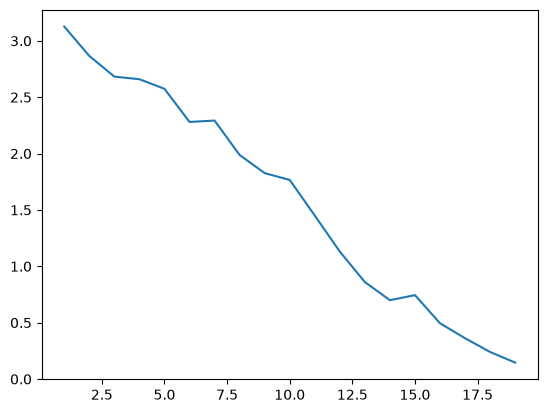

Final loss: 0.07721810787916183 - Steps: 20
Good job!


In [9]:
the_truth = "A quick brown fox did not jump over the lazy dog. Besides, that dog deserved it anyway!"
batch = tokenizer(the_truth, return_tensors='pt', return_token_type_ids=False).to(device)
space_for_prompts = torch.full([len(test_input_ids), num_prompts], fill_value=tokenizer.pad_token_id,
                               dtype=torch.int64, device=device)
batch['input_ids'] = torch.cat([space_for_prompts, batch['input_ids']], dim=1)
batch['attention_mask'] = torch.cat([torch.ones_like(space_for_prompts), batch['attention_mask']], dim=1)

loss_log = []
STEPS = 500
THRESHOLD = 0.1
for step_no in range(1, STEPS+1):
    outputs = model(**batch)
    next_word_logits = outputs.logits[:, num_prompts : -1, :]
    true_next_tokens = batch['input_ids'][:, num_prompts + 1:]
    loss = F.cross_entropy(next_word_logits.flatten(0, 1), true_next_tokens.flatten(0, 1))
    loss_log.append(loss.item())
    if loss.item() < THRESHOLD:
        break
    clear_output(wait=True)
    plt.plot(range(1, step_no+1), loss_log)
    plt.show()
    opt.zero_grad()
    loss.backward()
    opt.step()

outputs = model(**batch)
next_word_logits = outputs.logits[:, num_prompts : -1, :]
true_next_tokens = batch['input_ids'][:, num_prompts + 1:]
loss = F.cross_entropy(next_word_logits.flatten(0, 1), true_next_tokens.flatten(0, 1))
print("Final loss:", loss.item(), "- Steps:", step_no)

assert loss.item() <= 0.1
print("Good job!")

In [10]:
prompt = 'A quick brown fox'
batch = tokenizer(prompt, return_tensors='pt', return_token_type_ids=False).to(device)
batch['input_ids'] = torch.cat([space_for_prompts, batch['input_ids']], dim=1)
batch['attention_mask'] = torch.cat([torch.ones_like(space_for_prompts), batch['attention_mask']], dim=1)


for i in range(15):
    next_token = model(**batch).logits[0, -1].argmax(-1).reshape(1, 1)
    batch['input_ids'] = torch.cat([batch['input_ids'], next_token], dim=-1)
    batch['attention_mask'] = torch.cat([batch['attention_mask'], torch.ones_like(next_token)], dim=-1)

print("\nOutput:", tokenizer.decode(batch['input_ids'][0, num_prompts:].cpu().numpy().tolist()))

# if you did everything right, the model will deny that the fox jumped over the lazy dog


Output: A quick brown fox did not jump over the lazy dog. Besides, that dog deserved it anyway


### Using HuggingFace PEFT

[`peft`](https://huggingface.co/docs/peft/index) is a transformer's sister library that allows you to apply various **p**arameter **e**fficient **f**ine-**t**uning methods to pre-trained transformers. The library imlements both prompt tuning, prefix tuning, as well as several adapter-based techniques under a common interface:



In [3]:
import peft
assert isinstance(model.model.embed_tokens, nn.Embedding), "please reload the model"

peft_config = peft.PromptTuningConfig(task_type=peft.TaskType.CAUSAL_LM, num_virtual_tokens=16)
model = peft.get_peft_model(model, peft_config)  # note: for most peft methods, this line also modifies model in-place
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Total parameters (excluding quantization):", sum(p.numel() for p in model.parameters()))

Trainable parameters: 65536
Total parameters (excluding quantization): 4717917184


In [4]:
# Your task: optimize the PEFT-wrapped model to achieve next token prediction loss < 0.1, but this time using PEFT
# Please note: you no longer need to prepend PAD tokens, but you still need to skip :num_virtual_tokens: first logits.
# Finally, generate the sentence to make sure that the model learned the truth.

In [5]:
model.print_healthcheck()

PEFT healthcheck
Model:
  ID: unsloth/Qwen3-8B-Base-bnb-4bit, type: Qwen3ForCausalLM, adapters: default (PROMPT_TUNING)
Environment:
  peft: 0.22.0, transformers: 5.20.2, torch: 2.14.1+cu130, Python: 3.12.13
Runtime:
  training: True, devices: cuda, dtypes: float32=1,244,967,936, uint8=3,472,883,712, activation checkpointing: True
Parameters:
  trainable: 65,536, total: 8,190,800,896, percent trainable: 0.0008%
State:
  active: default, available: default


In [6]:
opt = torch.optim.Adam(model.parameters(), lr=0.01)

In [7]:
torch.cuda.empty_cache()

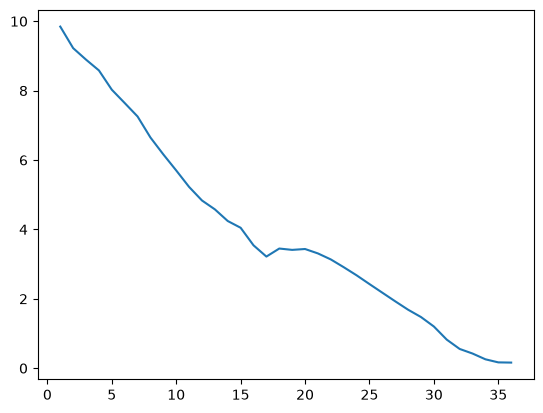

Final loss: 0.08208344876766205 - Steps: 37
Success!


In [8]:
the_truth = "A quick brown fox did not jump over the lazy dog. Besides, that dog deserved it anyway!"
batch = tokenizer(the_truth, return_tensors='pt', return_token_type_ids=False).to(device)
print(batch['input_ids'].shape)
# test_input_ids = tokenizer("a cat say on a mat", return_tensors='pt')['input_ids'].to(device)
# num_prompts = 16
# space_for_prompts = torch.full([len(test_input_ids), num_prompts], fill_value=tokenizer.pad_token_id,
#                                dtype=torch.int64, device=device)
# batch['input_ids'] = torch.cat([space_for_prompts, batch['input_ids']], dim=1)
# batch['attention_mask'] = torch.cat([torch.ones_like(space_for_prompts), batch['attention_mask']], dim=1)
print(batch['input_ids'].shape, batch['attention_mask'].shape)

loss_log = []
STEPS = 500
THRESHOLD = 0.1
for step_no in range(1, STEPS+1):
    outputs = model(**batch)
    next_word_logits = outputs.logits[:, peft_config.num_virtual_tokens :, :]
    true_next_tokens = batch['input_ids'].to(next_word_logits.device)
    loss = F.cross_entropy(next_word_logits.flatten(0, 1), true_next_tokens.flatten(0, 1))
    loss_log.append(loss.item())
    if loss.item() < THRESHOLD:
        break
    clear_output(wait=True)
    plt.plot(range(1, step_no+1), loss_log)
    plt.show()
    opt.zero_grad()
    loss.backward()
    opt.step()

outputs = model(**batch)
next_word_logits = outputs.logits[:, peft_config.num_virtual_tokens :, :]
true_next_tokens = batch['input_ids'].to(next_word_logits.device)
loss = F.cross_entropy(next_word_logits.flatten(0, 1), true_next_tokens.flatten(0, 1))
print("Final loss:", loss.item(), "- Steps:", step_no)

assert loss.item() <= 0.1
print("Success!")

In [9]:
# Feel free to structure your code as you see fit - as long as it's legible :)

In [ ]:
prompt = 'A quick brown fox'
batch = tokenizer(prompt, return_tensors='pt', return_token_type_ids=False).to(device)

for i in range(15):
    next_token = model(**batch).logits[0, -1].argmax(-1).reshape(1, 1)
    batch['input_ids'] = torch.cat([batch['input_ids'].to(next_token.device), next_token], dim=-1)
    batch['attention_mask'] = torch.cat([batch['attention_mask'].to(next_token.device), torch.ones_like(next_token)], dim=-1)

print("\nOutput:", tokenizer.decode(batch['input_ids'][0].cpu().numpy().tolist()))


Output: A quick brown fox fox fox fox fox fox fox fox fox fox fox fox fox fox fox fox


> Эээм

### Parameter-efficient finetuning with LoRA (1 point)

When training on more serious tasks, you can use low-rank adapters based on the [LoRA paper](https://arxiv.org/pdf/2106.09685.pdf).

The core idea is to add low-rank adapters __in parallel with existing linear layers,__ like this:
<center><img src="https://i.imgur.com/6bQLNiG.png" width=240px></center>

In the original LoRA paper, the adapters were only added to attention projection matrices. However, [subsequent works](https://arxiv.org/abs/2305.14314) show that it is useful to adapt FFNs as well. But before we do any training, we need to implement the basic LoRA layer.

In [2]:
import peft  # v-- re-load the notebook to remove any previous PEFT tuners, run cell 1 and this
model_name = 'unsloth/Qwen3-8B-Base-bnb-4bit'
tokenizer = transformers.AutoTokenizer.from_pretrained(model_name)
tokenizer.pad_token_id = tokenizer.eos_token_id
model = transformers.AutoModelForCausalLM.from_pretrained(
    model_name, device_map='auto', low_cpu_mem_usage=True, dtype=torch.float32,
    quantization_config=transformers.BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4"),
).to(device)
model = peft.prepare_model_for_kbit_training(model, use_gradient_checkpointing=True) # < checkpoints and input grads

/home/bojkoar/ysda_nlp_course/.venv3.12/lib/python3.12/site-packages/transformers/quantizers/auto.py:279: UserWarning: You passed `quantization_config` or equivalent parameters to `from_pretrained` but the model you're loading already has a `quantization_config` attribute. The `quantization_config` from the model will be used.
  warnings.warn(warning_msg)
[W1120 20:46:04.623595979 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 3 while trying to allocate 2489319424 bytes (free: 283246592, total: 8172666880).
Loading weights: 100%|██████████| 399/399 [00:02<00:00, 153.19it/s]
You shouldn't move a model that is dispatched using accelerate hooks.


In [7]:
class LoRALayer(nn.Module):
    """Wraps a linear layer with LoRA-like adapter. Wraps an existing OPT linear layer"""
    def __init__(self, module: nn.Linear, rank: int):
        super().__init__()
        self.module = module  # pre-trained (frozen) linear layer
        self.adapter_A = nn.Parameter(torch.empty(module.in_features, rank, device=module.weight.device))
        nn.init.kaiming_uniform_(self.adapter_A, a=5 ** 0.5)
        self.adapter_B = nn.Parameter(torch.zeros(rank, module.out_features, device=module.weight.device))

    def forward(self, input):
        # Apply self.module and LoRA adapter, return the sum (self.module outputs + adapter outputs)
        original_output = self.module(input)
        adapter_output = (input @ self.adapter_A) @ self.adapter_B
        return original_output + adapter_output

In [8]:
# test your implementation
test_linear = nn.Linear(128, 128)
test_linear.weight.data[...] = torch.eye(128)
test_adapter = LoRALayer(test_linear, rank=8)

assert torch.allclose(test_adapter(torch.ones(1, 1, 128)), test_linear.bias + 1), "please check your forward pass"

test_adapter.adapter_A.data[...] = torch.linspace(0.1, -0.5, 128 * 8).view(128, 8)
test_adapter.adapter_B.data[...] = torch.linspace(0.5, -0.1, 128 * 8).view(8, 128)
test_linear.bias.data[...] = torch.linspace(1., -1., 128)

dummy_loss = F.mse_loss(test_adapter(torch.ones(1, 128) / 128).squeeze(), torch.linspace(-1, 1, 128))
assert torch.allclose(dummy_loss, torch.tensor(1.3711389), rtol=0, atol=1e-4)
dummy_loss.backward()
assert all(w.grad is not None for w in [test_adapter.adapter_A, test_adapter.adapter_B]), "some adapter weights have no grad"
assert torch.allclose(test_adapter.adapter_A.grad.sum(), torch.tensor(-0.60158), rtol=0, atol=1e-4), "bad grad w.r.t. A"
assert torch.allclose(test_adapter.adapter_B.grad.sum(), torch.tensor(0.9931), rtol=0, atol=1e-4), "bad grad w.r.t. B"
# note: bad grad means that your code is different from LoRA paper OR that your code is not autograd-friendly (e.g. no_grad)
del dummy_loss, test_linear, test_adapter
print("All tests passed!")

All tests passed!


### Apply LoRA to the model

The code below applies LoRA adapters on top of Q/K/V linear layers in attention blocks. You may also choose to modify other layers:
* self_attn.o_proj - attention output projection
* mlp.up_proj, mlp.gate_proj, mlp.down_proj - transformer feedforward layers
* lm_head - output LM head

__Note:__ please scroll down for the homework task

In [ ]:
lora_rank = 8

for name, module in model.model.layers.named_modules():
    if 'DecoderLayer' in repr(type(module)):
        module.self_attn.q_proj = LoRALayer(module.self_attn.q_proj, rank=lora_rank).to(device)
        module.self_attn.k_proj = LoRALayer(module.self_attn.k_proj, rank=lora_rank).to(device)
        module.self_attn.v_proj = LoRALayer(module.self_attn.v_proj, rank=lora_rank).to(device)

assert sum(isinstance(module, LoRALayer) for module in model.modules()) > 0, "Did not add any LoRA layers!"

In [ ]:
batch = tokenizer("This model wants to share its greatest secret:", return_tensors='pt', return_token_type_ids=False).to(device)
# test a single training step, make sure we get meaningful gradients
with torch.cuda.amp.autocast(dtype=torch.float32):
    out = model.forward(**batch)
    (out.logits.norm() / 100).backward()

for i, module in enumerate(model.modules()):
    if isinstance(module, LoRALayer):
        assert module.adapter_B.grad is not None
        assert module.adapter_B.grad.norm().item() > 0

model.zero_grad(set_to_none=True)
print("Grad check successful, well done!")

Grad check successful, well done!


### (example) How to train your model

The example below shows how to train the LoRA adapters on a dummy dataset. You will need to run a _similar_ training task later.

__Note:__ please scroll down for the homework task

In [ ]:
# checking if the model can learn. Change max_steps for proper training
import datasets
data = datasets.load_dataset("Abirate/english_quotes", split="train[:32]") # 32 lines
data = data.map(lambda samples: tokenizer(samples['quote']), batched=True)
model._hf_peft_config_loaded = True  # silence a warning from HF trainer

trainer = transformers.Trainer(
    model=model, train_dataset=data,
    args=transformers.TrainingArguments(
        per_device_train_batch_size=2, gradient_accumulation_steps=1,
        # note: if you want larger batch size, increase gradient_accumulation_steps
        warmup_steps=250, max_steps=100, learning_rate=2e-4, fp16=True,
        logging_steps=1, output_dir='outputs', report_to="tensorboard"),
    data_collator=transformers.DataCollatorForLanguageModeling(tokenizer, mlm=False)
)
# if you see cache warnings, set `model.config.use_cache = False` to silence them. Please re-enable for inference!

trainer.train()

# NOTE: this is just an example! you do not have to wait for this progressbar to finish :)

/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step,Training Loss
1,1.289705
2,0.375477
3,1.699360
4,1.195340
5,0.786238
6,1.737145
7,1.637755
8,1.208393
9,0.634554
10,1.270690


Step,Training Loss
1,1.289705
2,0.375477
3,1.699360
4,1.195340
5,0.786238
6,1.737145
7,1.637755
8,1.208393
9,0.634554
10,1.270690


### Final task: *actually* train the model (3 points)

Your task is to fine-tune the model to _generate python code_. Please use the above examples for inspiration. More specifically,

* __dataset:__ use [codeparrot-clean](https://huggingface.co/datasets/codeparrot/codeparrot-clean) or any other data containing python code. Since you do not need much data for this excercise, it is enough to use just shorter validation subset of `codeparrots`
* __preprocessing:__ select python code based on file extentions (.py)  (may skip in case of codeparrot - it is 100% python)
* __short lines:__ please take the first 512 characters of each line
* __adapter type:__ please use LoRA as defined above __plus at least one of:__
   - extra adapter on lm_head
   - extra adapter on MLP components (mlp.*)
   - trainable input embeddings (requires tweaking memory usage)

* __training:__ you do not have to train to convergence. If all goes well, your model should `.generate` code after 500 steps. Please use batch size of at least 4 (4 x 1 x 512 tokens) using `gradient_accumulation_steps=4`.


Note: the peft library also has LoRA implementation. However, we ask that for this assignment you show at least one complete training run with your own LoRA code.

__Alternative assignment:__ Instead of doing python code, feel free to substitute the task with any other dataset, e.g. your favorite artist or podcast, as long as it's ethical. If you choose your own task, please show examples of what your model learned - or did not learn, akin to the code examples below.

In [ ]:
prompts =  ['', 'import', 'from', 'while', 'try', 'if', 'for', 'torch']  # feel free to add a few more that are not 100% assiciated with Python

# <A WHOLE LOT OF YOUR CODE>
# generate baseline samples with the selected prompts before finetuning
# please feel free to use transformers.Trainer (as above) or your custom training code
# after the training concludes, please show examples of text generated by your model. It is expected to look like Python code fragments
# print the generation examples nicely (suggestion: use pandas or HTML) for easier comparison
# note: your LoRA-enhanced model can run generation the same way as the non-trained model (above)

In [ ]:
# This template helps to compare generated code samples in pretty table form
# feel free to present your work in other forms

from IPython.display import HTML, display
table_template = """<table style="border:1px solid black" >
  <tr>
    <th style="text-align: center; border:1px solid black">PROMPT</th>
    <th style="text-align: center; border:1px solid black">BEFORE</th>
    <th style="text-align: center; border:1px solid black">AFTER</th>
  </tr>
{}
</table>"""

row_template = '''  <tr>
    <td style="width:20%; border:1px solid black"><pre align="left">`{}`</pre></td>
    <td style="width:40%; border:1px solid black"><pre align="left">{}</pre></td>
    <td style="width:40%; border:1px solid black"><pre align="left">{}</pre></td>
  </tr>'''

rows = []

for prompt in prompts:
    # replace placeholders in the format() arguments
    rows.append(row_template.format(prompt, "BEFORE FINETUNING", "TO BE GENERATED AFTER FINETUNING"))

display(HTML(table_template.format('\n'.join(rows))))

PROMPT,BEFORE,AFTER
``,BEFORE FINETUNING,TO BE GENERATED AFTER FINETUNING
`import`,BEFORE FINETUNING,TO BE GENERATED AFTER FINETUNING
`from`,BEFORE FINETUNING,TO BE GENERATED AFTER FINETUNING
`while`,BEFORE FINETUNING,TO BE GENERATED AFTER FINETUNING
`try`,BEFORE FINETUNING,TO BE GENERATED AFTER FINETUNING
`if`,BEFORE FINETUNING,TO BE GENERATED AFTER FINETUNING
`for`,BEFORE FINETUNING,TO BE GENERATED AFTER FINETUNING
`torch`,BEFORE FINETUNING,TO BE GENERATED AFTER FINETUNING


If you reach this: congratulations! you've completed everything in this practice session.

If you want to dig deeper, try to implement prompt-tuning (for bonus points!).
You can read more about prompt tuning variants in paper [1](https://arxiv.org/abs/2104.08691) or paper [2](https://arxiv.org/abs/2101.00190). Both versions can be implemented by passing trainable prompts as `model.forward(..., past_key_values=your_prompts)`.



### Read more

* How post-training quantization works: https://arxiv.org/abs/2208.07339
* An overview of running large models: https://huggingface.co/docs/accelerate/package_reference/big_modeling
* A general library for different adapter types: https://adapterhub.ml/


### [extra info] Running other models.

This notebook's code can run with other models of similar size, such as [Falcon-7B](https://huggingface.co/tiiuae/falcon-7b), [OPT-6.7B](https://huggingface.co/facebook/opt-6.7b) or [BLOOM-7.1B](https://huggingface.co/bigscience/bloom-7b1). However, they will require minor code tweaks:
1. change the model name in `AutoModelForCausalLM.from_pretrained()` __and__ `AutoTokenizer`
2. In the prompt tuning code, change `model.model.embed_tokens` to refer to the target model's word embeddings. Simply `print(model)` to navigate to them.
3. Change code to add Lora layers - specifically where you what the transformer block components, since those components now have different names.